# Síntese demográfica

Mesmo gráfico de `demographic_graphic.ipynb`, agora alimentado por `../data/dados_demograficos.csv` (as 7 primeiras colunas da FAT revisada: *Paper Style*, *Maturity Level*, *Is this work from?* e o ano).

Saída: `demografia.pdf` e `demografia.png`, nesta pasta.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import sys
sys.path.insert(0, "../scripts")   # graficos/scripts/paleta.py
from paleta import tons

In [2]:
dados = pd.read_csv('../data/dados_demograficos.csv', dtype=str)
dados['Year'] = dados['Year'].astype(int)
years = [2023, 2024, 2025, 2026]

# O CSV está em português; os rótulos do gráfico seguem em inglês, na mesma ordem do gráfico original.
veiculo = {'Conferência': 'Conference', 'Periódico': 'Journal', 'Workshop': 'Workshop', 'Preprint': 'Preprint'}
afiliacao = {'Academia': 'Academia', 'Academia e indústria': 'Academia and Industry',
             'Academia e centro de pesquisa': 'Academia and Research Center', 'Indústria': 'Industry',
             'Centro de pesquisa': 'Research Center',
             'Academia, centro de pesquisa e indústria': 'Academia, Research Center and Industry',
             'Indústria e centro de pesquisa': 'Industry and Research Center'}
pesquisa = {'Pesquisa de validação': 'Validation Research', 'Pesquisa de avaliação': 'Evaluation Research',
            'Proposta de solução': 'Solution Research', 'Proposta conceitual': 'Conceptual Proposal',
            'Relato de experiência': 'Experience Paper'}


def por_ano(coluna, rotulos, outros=None):
    """Estudos por ano (linhas) e categoria (colunas), com as categorias na ordem de `rotulos`."""
    categoria = dados[coluna].map(rotulos)
    if outros:                                   # o que não está em `rotulos` cai em `outros`
        categoria = categoria.fillna(outros)
    assert categoria.notna().all(), f'categoria sem rótulo em {coluna}: {set(dados.loc[categoria.isna(), coluna])}'
    ordem = list(dict.fromkeys(rotulos.values())) + ([outros] if outros else [])
    return pd.crosstab(dados['Year'], categoria).reindex(index=years, columns=ordem, fill_value=0)


# Tipo de veículo (Paper Style)
ct_tipo = por_ano('Paper Style', veiculo)

# Afiliação (Is this work from?) — as três linhas "independente" formam a categoria Independent
ct_madeby = por_ano('Is this work from?', afiliacao, outros='Independent')

# Tipo de pesquisa (Maturity Level) — linhas = categorias, colunas = anos
ct_matutiry = por_ano('Maturity Level', pesquisa).T

# Conferência dos totais
totais = pd.DataFrame({
    'veículo': ct_tipo.sum(axis=1),
    'afiliação': ct_madeby.sum(axis=1),
    'pesquisa': ct_matutiry.sum(axis=0),
})
print(totais)
print('Total:', totais.sum().to_dict())
assert (totais.nunique(axis=1) == 1).all(), 'totais por ano não batem'
assert totais['veículo'].sum() == len(dados)


      veículo  afiliação  pesquisa
Year                              
2023       26         26        26
2024       91         91        91
2025      238        238       238
2026      146        146       146
Total: {'veículo': 501, 'afiliação': 501, 'pesquisa': 501}


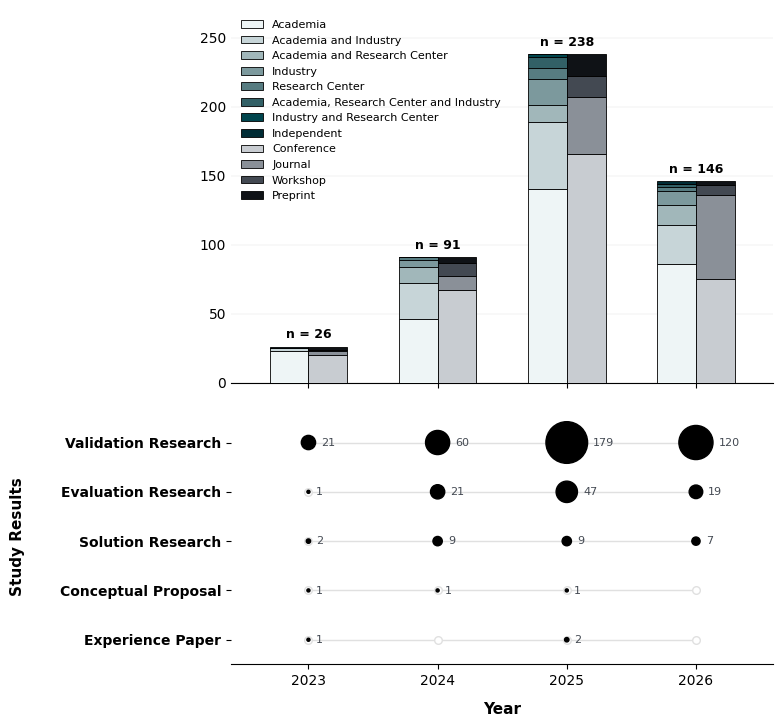

In [3]:
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(7, 8.5), sharex=True,
                               gridspec_kw={'height_ratios': [1.6, 1.1]})
plt.subplots_adjust(hspace=0.08)
width = 0.3
anos = np.array(years)

# --- Painel 1: afiliação (esquerda) e veículo (direita) empilhados ---
# paleta compartilhada (graficos/paleta.py): rampa do tom mais claro ao mais escuro
cores_barras_mb = tons(len(ct_madeby.columns))[::-1]
bottoms = np.zeros(len(anos))
for i, paper_made in enumerate(ct_madeby.columns):
    valores = ct_madeby[paper_made].values
    ax1.bar(anos - width/2, valores, width, bottom=bottoms, label=paper_made,
            color=cores_barras_mb[i], edgecolor='black', linewidth=0.6, zorder=3)
    bottoms += valores

cores_barras = ['#c8ccd1', '#8a9098', '#434952', '#0f1216']   # veículo em cinza, para separar da afiliação
bottoms = np.zeros(len(anos))
for i, paper_type in enumerate(ct_tipo.columns):
    valores = ct_tipo[paper_type].values
    ax1.bar(anos + width/2, valores, width, bottom=bottoms, label=paper_type,
            color=cores_barras[i], edgecolor='black', linewidth=0.6, zorder=3)
    bottoms += valores

# total de estudos por ano acima das barras
for x, total in zip(anos, ct_tipo.sum(axis=1).values):
    ax1.text(x, total + 4, f'n = {total}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.legend(loc='upper left', frameon=False, fontsize=8, ncol=1)
ax1.set_ylim(0, 270)
# ax1.set_ylabel('Number of studies', fontweight='bold', fontsize=11)
for s in ['top', 'right', 'left']:
    ax1.spines[s].set_visible(False)
ax1.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.2, zorder=0)
ax1.set_axisbelow(True)
ax1.tick_params(axis='y', length=0)

# --- Painel 2: tipo de pesquisa (bolhas) ---
maturities = ct_matutiry.index
escala = 900 / ct_matutiry.values.max()   # área da bolha proporcional à contagem

for i, maturity in enumerate(reversed(maturities)):
    eixo_y = [i] * len(anos)
    ax2.plot(anos, eixo_y, color='#e0e0e0', zorder=0, linewidth=1)
    ax2.scatter(anos, eixo_y, s=30, color='white', edgecolors='#e0e0e0', zorder=1)
    valores = ct_matutiry.loc[maturity].values
    ax2.scatter(anos, eixo_y, s=valores * escala, color='black', zorder=2)
    for x, v in zip(anos, valores):
        if v > 0:
            raio = np.sqrt(v * escala) / 2           # raio em pontos
            ax2.annotate(str(v), (x, i), xytext=(raio + 4, 0), textcoords='offset points',
                         ha='left', va='center', fontsize=8, color='#434952')

ax2.set_yticks(range(len(maturities)))
ax2.set_yticklabels(list(reversed(maturities)), fontweight='bold', fontsize=10)
ax2.set_ylabel('Study Results', fontweight='bold', fontsize=11, labelpad=25)
lo, hi = ax2.get_ylim()
ax2.set_ylim(lo - 0.3, hi + 0.5)
for s in ['top', 'right', 'left']:
    ax2.spines[s].set_visible(False)
ax2.grid(False)

ax2.set_xlim(anos[0] - 0.6, anos[-1] + 0.6)
plt.xticks(years, rotation=0, fontsize=10)
ax2.set_xlabel('Year', fontweight='bold', fontsize=11, labelpad=10)

plt.savefig('demografia.pdf', bbox_inches='tight')
plt.savefig('demografia.png', bbox_inches='tight', dpi=300)
plt.show()
plt.close()